# 01 Learning Problem EDA: Data Understanding

Notebook ini adalah bagian Data Understanding untuk proyek Deteksi Aktivitas Deforestasi Hutan Tropis melalui Klasifikasi Multi-Label Citra Satelit (Kelompok 10, SDG 15 target 15.2). Isinya tiga hal: informasi dataset dan deskripsi fitur, analisis kondisi data (missing values, duplikat, outlier, imbalance, noise), dan eksplorasi data (EDA) dengan visualisasi beserta insight tertulisnya. Notebook ini tidak mengubah data apa pun; perubahan data adalah pekerjaan notebook 02_data_preparation.

Dataset: Planet: Understanding the Amazon from Space (Kaggle). Yang dipakai adalah set latih kompetisi: berkas citra train-jpg dan berkas label train_v2.csv.

In [1]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
print("Root proyek:", ROOT)

Root proyek: /home/hatch/workspace/learning-problem-deforestasi


## 1. Informasi dataset

| Aspek | Isi |
|---|---|
| Nama dataset | Planet: Understanding the Amazon from Space |
| Sumber | Kaggle, kompetisi tahun 2017 |
| Wilayah dan waktu rekam | Cekungan Amazon, 1 Januari 2016 sampai 1 Februari 2017 |
| Jumlah baris label | 40.479 baris pada train_v2.csv |
| Kolom | image_name (nama citra) dan tags (daftar label, dipisahkan spasi) |
| Berkas citra | JPG, 256 kali 256 piksel, 3 kanal warna RGB, resolusi 3,7 meter per piksel |
| Format alternatif | TIF 4 kanal termasuk inframerah dekat, tidak dipakai pada proyek ini |
| Jumlah label | 17 label, satu citra dapat memiliki banyak label sekaligus |
| Ukuran berkas | train-jpg.tar.7z sekitar 629 MB, train_v2.csv sekitar 1 MB |

In [2]:
import pandas as pd

df = pd.read_csv(RAW / "train_v2.csv", dtype=str)
print("Bentuk data (baris, kolom):", df.shape)
print("Tipe data tiap kolom:")
print(df.dtypes)
print()
print("Lima baris pertama:")
print(df.head())
print()
jumlah_jpg = len(list((RAW / "train-jpg").glob("*.jpg")))
print("Jumlah berkas JPG di folder train-jpg:", jumlah_jpg)

Bentuk data (baris, kolom): (40479, 2)
Tipe data tiap kolom:
image_name    str
tags          str
dtype: object

Lima baris pertama:
  image_name                                       tags
0    train_0                               haze primary
1    train_1            agriculture clear primary water
2    train_2                              clear primary
3    train_3                              clear primary
4    train_4  agriculture clear habitation primary road



Jumlah berkas JPG di folder train-jpg: 40479


### Tabel deskripsi fitur

Pada data citra ini, fitur targetnya adalah 17 label berikut. Kolom jumlah adalah jumlah citra yang memiliki label itu pada data mentah, dihitung berdasarkan kehadiran per citra.

| Label | Kelompok | Deskripsi | Jumlah citra |
|---|---|---|---|
| clear | Cuaca | Cuaca cerah, citra jernih tanpa tutupan awan | 28.431 |
| partly_cloudy | Cuaca | Sebagian wilayah citra tertutup awan | 7.261 |
| haze | Cuaca | Citra berkabut atau berasap tipis | 2.697 |
| cloudy | Cuaca | Seluruh citra tertutup awan | 2.089 |
| primary | Tutupan dan penggunaan lahan umum | Hutan primer atau hutan yang masih utuh | 37.513 |
| water | Tutupan dan penggunaan lahan umum | Badan air seperti sungai atau danau | 7.411 |
| habitation | Tutupan dan penggunaan lahan umum | Permukiman atau bangunan tempat tinggal | 3.660 |
| agriculture | Tutupan dan penggunaan lahan umum | Lahan pertanian atau perkebunan skala besar | 12.315 |
| cultivation | Tutupan dan penggunaan lahan umum | Lahan budidaya atau pengolahan lahan skala kecil | 4.477 |
| road | Tutupan dan penggunaan lahan umum | Jalan yang membelah atau berada di dalam wilayah citra | 8.071 |
| bare_ground | Jarang muncul | Tanah terbuka tanpa tutupan vegetasi | 862 |
| blooming | Jarang muncul | Tumbuhan berbunga musiman, gejala alam | 332 |
| blow_down | Jarang muncul | Pohon tumbang karena angin, gejala alam | 98 |
| slash_burn | Jarang muncul | Lahan bekas tebang bakar oleh manusia | 209 |
| selective_logging | Jarang muncul | Penebangan selektif, tampak pola tebangan sebagian | 340 |
| artisinal_mine | Jarang muncul | Pertambangan rakyat skala kecil | 339 |
| conventional_mine | Jarang muncul | Pertambangan konvensional atau industri | 100 |

## 2. Analisis kondisi data

Lima hal diperiksa: nilai hilang (missing values), duplikat, outlier, ketidakseimbangan (imbalance), dan noise atau label berisik.

In [3]:
# Missing values dan duplikat
print("Nilai kosong per kolom:")
print(df.isna().sum())
print()
print("Baris dengan tags kosong:", int((df["tags"].fillna("") == "").sum()))
print("Duplikat image_name:", int(df.duplicated(subset="image_name").sum()))
token_ganda = int(sum(1 for t in df["tags"] if len(t.split()) != len(set(t.split()))))
print("Baris dengan token label tertulis ganda:", token_ganda)
nama_disk = {p.stem for p in (RAW / "train-jpg").glob("*.jpg")}
print("Nama di CSV tetapi berkasnya tidak ada di disk:", len(set(df["image_name"]) - nama_disk))
print("Berkas di disk tetapi tidak ada di CSV:", len(nama_disk - set(df["image_name"])))

Nilai kosong per kolom:
image_name    0
tags          0
dtype: int64

Baris dengan tags kosong: 0
Duplikat image_name: 0
Baris dengan token label tertulis ganda: 73


Nama di CSV tetapi berkasnya tidak ada di disk: 0
Berkas di disk tetapi tidak ada di CSV: 0


In [4]:
# Jumlah label per citra (pemeriksaan sebaran dan outlier sederhana)
jumlah_label = df["tags"].str.split().apply(len)
print(jumlah_label.describe())
print("Jumlah label minimum:", int(jumlah_label.min()), "| maksimum:", int(jumlah_label.max()))

count    40479.000000
mean         2.872551
std          1.222771
min          1.000000
25%          2.000000
50%          2.000000
75%          4.000000
max          9.000000
Name: tags, dtype: float64
Jumlah label minimum: 1 | maksimum: 9


**Temuan kondisi data:**

- **Missing values:** tidak ada nilai kosong pada kedua kolom dan tidak ada berkas citra yang hilang dari disk. Satu satunya kekurangan bersifat label: satu baris, train_24448, tidak memiliki label cuaca, dan itu ditangani pada tahap preparation.
- **Duplikat:** tidak ada image_name duplikat. Ada 73 baris yang token labelnya tertulis ganda di dalam tags; ini bukan duplikat data, melainkan cara penulisan, dan diatasi dengan menghitung label berdasarkan kehadiran per citra.
- **Outlier:** data ini data citra, jadi outlier tidak diperiksa seperti data tabel. Pemeriksaan yang relevan adalah sebaran jumlah label per citra: rata rata 2,87 label, minimum 1, maksimum 9, dan tidak ada citra tanpa label sama sekali. Pemeriksaan integritas berkas (semua citra terbaca) dilakukan di notebook preparation dan hasilnya nol citra rusak.
- **Imbalance:** sangat ekstrem, dirinci pada visualisasi pertama di bawah. Label terbanyak primary 37.513 citra (92,68 persen), label terjarang blow_down 98 citra (0,24 persen), rasio sekitar 383 banding 1.
- **Noise:** label dibuat secara crowdsourcing oleh banyak pelabel manusia, sehingga sebagian label bersifat ambigu dan dapat keliru. Ini risiko utama kualitas data proyek ini dan diakui terbuka; penanganannya adalah metrik per label dan analisis kesalahan pada tahap evaluasi, bukan menghapus data secara sembarangan.

## 3. EDA dan insight

### Visualisasi 1: Distribusi 17 label

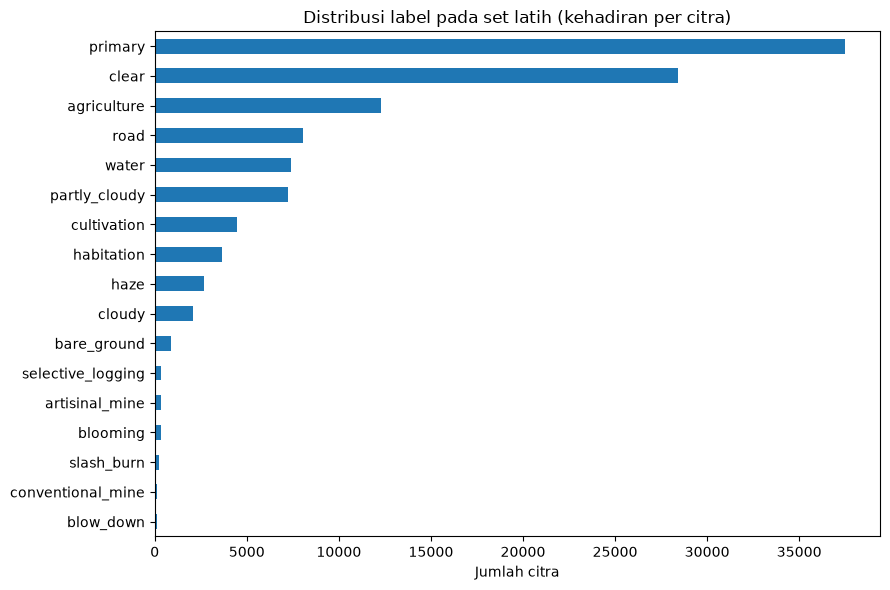

primary              37513
clear                28431
agriculture          12315
road                  8071
water                 7411
partly_cloudy         7261
cultivation           4477
habitation            3660
haze                  2697
cloudy                2089
bare_ground            862
selective_logging      340
artisinal_mine         339
blooming               332
slash_burn             209
conventional_mine      100
blow_down               98
dtype: int64


In [5]:
import matplotlib.pyplot as plt

hitung = {}
for t in df["tags"]:
    for lab in set(t.split()):
        hitung[lab] = hitung.get(lab, 0) + 1
distribusi = pd.Series(hitung).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
distribusi.plot(kind="barh", ax=ax)
ax.set_xlabel("Jumlah citra")
ax.set_title("Distribusi label pada set latih (kehadiran per citra)")
plt.tight_layout()
plt.show()
print(distribusi.sort_values(ascending=False))

**Insight 1, ketidakseimbangan ekstrem.** primary muncul pada 92,68 persen citra, artinya sebagian besar wilayah masih hutan utuh. Empat label inti aktivitas manusia penyebab deforestasi semuanya langka: slash_burn 209, selective_logging 340, artisinal_mine 339, conventional_mine 100. Akibatnya akurasi tidak layak jadi ukuran utama, karena model yang selalu menebak label umum akan tampak pintar. Proyek ini memakai F2-score dan recall per label, dan pembagian datanya harus stratified supaya label langka tetap terwakili di semua bagian.

### Visualisasi 2: Jumlah label per citra

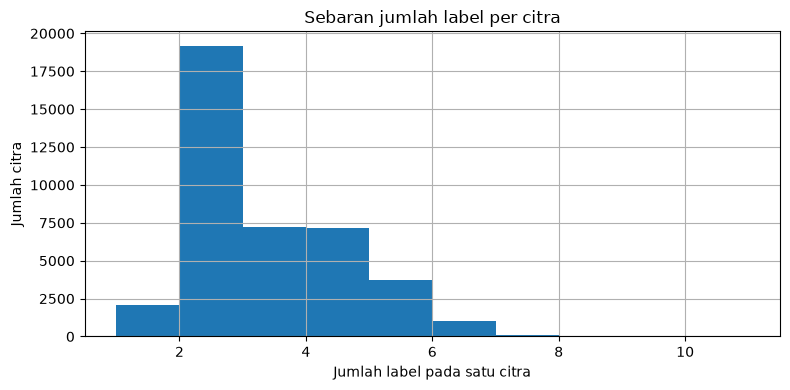

Rata rata label per citra: 2.87


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
jumlah_label.hist(bins=range(1, 12), ax=ax)
ax.set_xlabel("Jumlah label pada satu citra")
ax.set_ylabel("Jumlah citra")
ax.set_title("Sebaran jumlah label per citra")
plt.tight_layout()
plt.show()
print("Rata rata label per citra:", round(float(jumlah_label.mean()), 2))

**Insight 2, multi-label memang nyata.** Rata rata satu citra memiliki 2,87 label dan paling banyak 9 label. Satu potret memang bisa berisi hutan, sungai, dan jalan sekaligus, jadi tugasnya benar klasifikasi multi-label dengan keluaran 17 keputusan ya atau tidak, bukan memilih satu kelas.

### Visualisasi 3: Ko-okurensi label cuaca

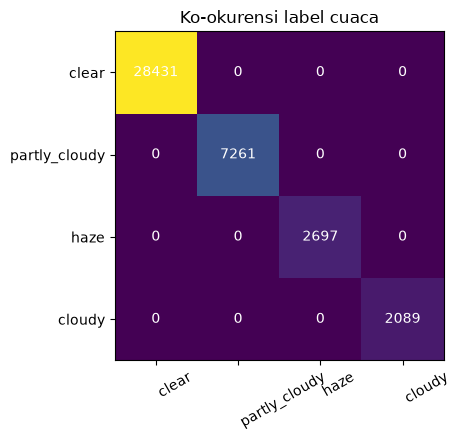

               clear  partly_cloudy  haze  cloudy
clear          28431              0     0       0
partly_cloudy      0           7261     0       0
haze               0              0  2697       0
cloudy             0              0     0    2089


In [7]:
CUACA = ["clear", "partly_cloudy", "haze", "cloudy"]
ko = pd.DataFrame(0, index=CUACA, columns=CUACA, dtype=int)
for t in df["tags"]:
    labs = set(t.split())
    for a in CUACA:
        for b in CUACA:
            if a in labs and b in labs:
                ko.loc[a, b] += 1

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(ko.values)
ax.set_xticks(range(4)); ax.set_xticklabels(CUACA, rotation=30, ha="left")
ax.set_yticks(range(4)); ax.set_yticklabels(CUACA)
for i in range(4):
    for j in range(4):
        ax.text(j, i, str(ko.values[i, j]), ha="center", va="center", color="white")
ax.set_title("Ko-okurensi label cuaca")
plt.tight_layout()
plt.show()
print(ko)

**Insight 3, cuaca saling lepas.** Pada data bersih, setiap citra memiliki tepat satu label cuaca, jadi sel di luar diagonal seharusnya nol sesudah preparation. clear mendominasi dengan 28.431 citra, cloudy paling sedikit 2.089 citra. Dominasi clear menguntungkan pemodelan karena isi lahan terlihat, tetapi model tetap harus menghadapi citra berawan dan berkabut yang lebih sulit.

### Visualisasi 4: Contoh citra per label

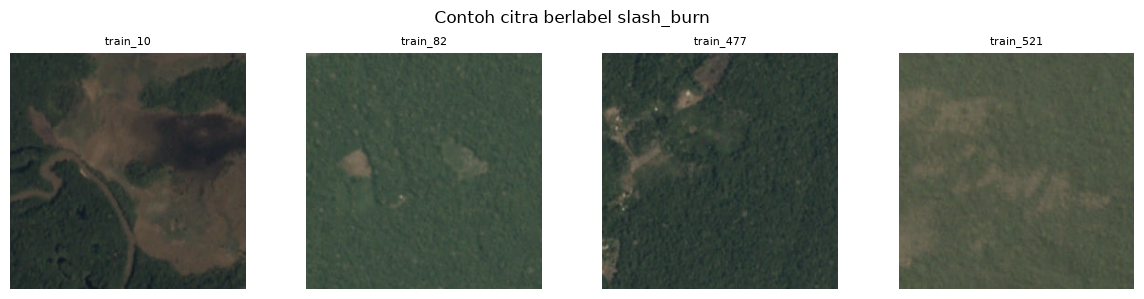

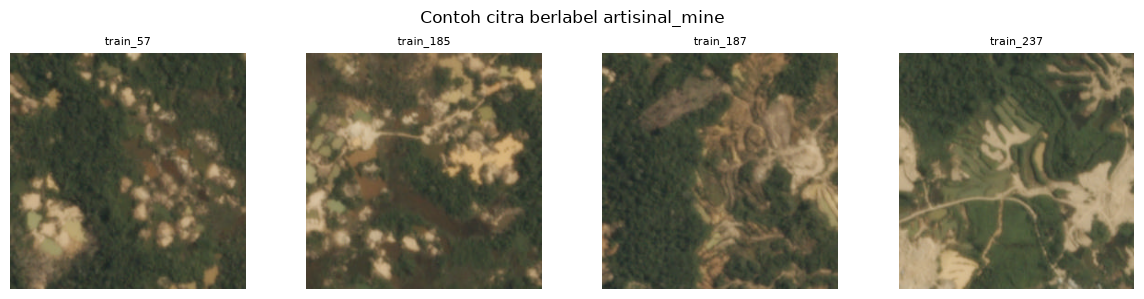

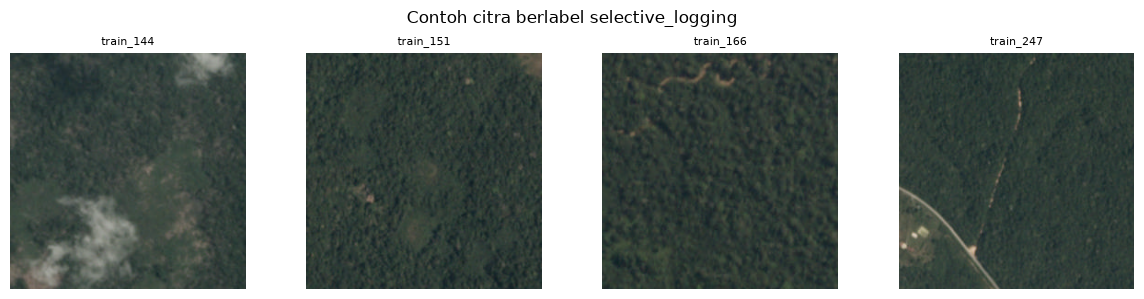

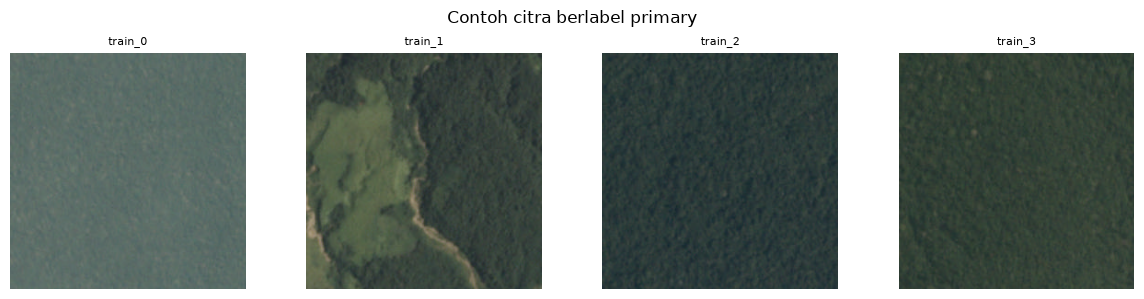

In [8]:
from PIL import Image

def tampilkan_contoh(label, n=4):
    nama = df[df["tags"].str.contains(label)]["image_name"].head(n).tolist()
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    if n == 1:
        axes = [axes]
    for ax, nm in zip(axes, nama):
        ax.imshow(Image.open(RAW / "train-jpg" / f"{nm}.jpg"))
        ax.set_title(nm, fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Contoh citra berlabel {label}")
    plt.tight_layout()
    plt.show()

for lab in ["slash_burn", "artisinal_mine", "selective_logging", "primary"]:
    tampilkan_contoh(lab)

**Insight 4, kesulitan label tidak sama.** Pola slash_burn dan tambang relatif mudah dikenali mata: bekas bakar gelap dan galian serta kolam tambang kontras dengan hutan hijau. Pola selective_logging jauh lebih halus karena hutannya masih tampak utuh dari atas. Dari sini sudah bisa diperkirakan selective_logging akan menjadi label tersulit bagi model, dan inilah alasan evaluasi harus dilaporkan per label, bukan hanya satu angka global.

## 4. Kesimpulan Data Understanding

Dataset terunduh utuh dan bersih dari masalah berkas: tidak ada nilai hilang, tidak ada duplikat nama, tidak ada citra rusak. Masalah data yang sesungguhnya ada tiga: ketidakseimbangan label yang ekstrem (383 banding 1), noise label dari anotasi crowdsourcing, dan satu baris tanpa label cuaca. Ketiganya ditangani pada tahap Data Preparation di notebook 02_data_preparation: aturan cleaning mengikuti aturan resmi dataset, pembagian data stratified dengan seed tetap, dan penanganan imbalance lewat pilihan metrik serta threshold pada tahap pemodelan.